In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
conn=sqlite3.connect(r"C:\Users\Soni\first_project\data\inventory.db")
tables=pd.read_sql_query("Select name from sqlite_master where type='table'",conn)

In [3]:
for table in tables['name']:
    print('Table name ',table)
    df=pd.read_sql_query(f"select*from {table} limit 5",conn)
    display(df)

Table name  purchases


,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification
0,69_MOUNTMEND_8412,69,8412,Tequila Ocho Plata Fresno,750mL,105,ALTAMAR BRANDS LLC,8124,2023-12-21,2024-01-02,2024-01-04,2024-02-16,35.71,6,214.26,1
1,30_CULCHETH_5255,30,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,4,37.40,1
2,34_PITMERDEN_5215,34,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-02,2024-01-07,2024-02-21,9.41,5,47.05,1
3,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,6,56.10,1
4,76_DONCASTER_2034,76,2034,Glendalough Double Barrel,750mL,388,ATLANTIC IMPORTING COMPANY,8169,2023-12-24,2024-01-02,2024-01-09,2024-02-16,21.32,5,106.60,1


Table name  purchase_prices


,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,58,Gekkeikan Black & Gold Sake,12.99,750mL,750,1,9.28,8320,SHAW ROSS INT L IMP LTD
1,62,Herradura Silver Tequila,36.99,750mL,750,1,28.67,1128,BROWN-FORMAN CORP
2,63,Herradura Reposado Tequila,38.99,750mL,750,1,30.46,1128,BROWN-FORMAN CORP
3,72,No. 3 London Dry Gin,34.99,750mL,750,1,26.11,9165,ULTRA BEVERAGE COMPANY LLP
4,75,Three Olives Tomato Vodka,14.99,750mL,750,1,10.94,7245,PROXIMO SPIRITS INC.


Table name  vendor_invoice


,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None


Table name  begin_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6,36.99,2024-01-01
3,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,3,38.99,2024-01-01
4,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,6,34.99,2024-01-01


Table name  end_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7,38.99,2024-12-31
3,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,4,34.99,2024-12-31
4,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,750mL,7,14.99,2024-12-31


In [4]:
purchase_agg_df=pd.read_sql_query("""
select
p.PONumber,
count(distinct p.Brand) as total_brands,
sum(p.Quantity) as total_item_quantity,
sum(p.Dollars) as total_item_dollars,
avg(julianday(p.ReceivingDate) - julianday(p.PODate)) as avg_receiving_delay

from purchases p
group by p.PONumber
""",conn)

In [5]:
pd.read_sql_query("""
select 
*
from vendor_invoice vi
""",conn)

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None
...,...,...,...,...,...,...,...,...,...,...
5538,9622,WEIN BAUER INC,2025-01-06,13626,2024-12-21,2025-02-10,90,1563.00,8.60,None
5539,9625,WESTERN SPIRITS BEVERAGE CO,2025-01-10,13661,2024-12-23,2025-02-18,4617,37300.48,186.50,None
5540,3664,WILLIAM GRANT & SONS INC,2025-01-02,13643,2024-12-22,2025-02-04,9848,202815.78,932.95,None
5541,9815,WINE GROUP INC,2025-01-03,13602,2024-12-20,2025-02-08,24747,149007.56,819.54,None


In [6]:
pd.read_sql_query("""
select

vi.PONumber,
vi.Quantity as invoice_quantity,
vi.Dollars as invoice_dollars,
vi.freight,
(julianday(vi.InvoiceDate) - julianday(vi.PODate)) as days_po_to_invoice,
(julianday(vi.PayDate) - julianday(vi.InvoiceDate)) as days_to_pay
from vendor_invoice vi
""",conn)


,PONumber,invoice_quantity,invoice_dollars,Freight,days_po_to_invoice,days_to_pay
0,8124,6,214.26,3.47,14.0,43.0
1,8137,15,140.55,8.57,16.0,45.0
2,8169,5,106.60,4.61,16.0,38.0
3,8106,10100,137483.78,2935.20,23.0,24.0
4,8170,1935,15527.25,429.20,14.0,36.0
...,...,...,...,...,...,...
5538,13626,90,1563.00,8.60,16.0,35.0
5539,13661,4617,37300.48,186.50,18.0,39.0
5540,13643,9848,202815.78,932.95,11.0,33.0
5541,13602,24747,149007.56,819.54,14.0,36.0


In [7]:
df=pd.read_sql_query("""
WITH purchase_agg as(
    select
        p.PONumber,
        count(distinct p.Brand) as total_brands,
        sum(p.Quantity) as total_item_quantity,
        sum(p.Dollars) as total_item_dollars,
        avg(julianday(p.ReceivingDate) - julianday(p.PODate)) as avg_receiving_delay

    from purchases p
    group by p.PONumber
)
select
    vi.PONumber,
    vi.Quantity as invoice_quantity,
    vi.Dollars as invoice_dollars,
    vi.freight,
    (julianday(vi.InvoiceDate) - julianday(vi.PODate)) as days_po_to_invoice,
    (julianday(vi.PayDate) - julianday(vi.InvoiceDate)) as days_to_pay,
    pa.total_brands,
    pa.total_item_quantity,
    pa.total_item_dollars,
    pa.avg_receiving_delay
from vendor_invoice vi
left join purchase_agg pa
    on vi.PONumber = pa.PONumber 
""",conn)

In [12]:
def create_invoice_risk_label(row):

    #invoice total mismatch with item-level total
    if (abs(row['invoice_dollars']-row['total_item_dollars'])>5):
        return 1
    if row['avg_receiving_delay']>10:
        return 1
    return 0

df['flag_invoice']=df.apply(create_invoice_risk_label,axis=1)
df['flag_invoice'].value_counts()

flag_invoice
0    3693
1    1850
Name: count, dtype: int64

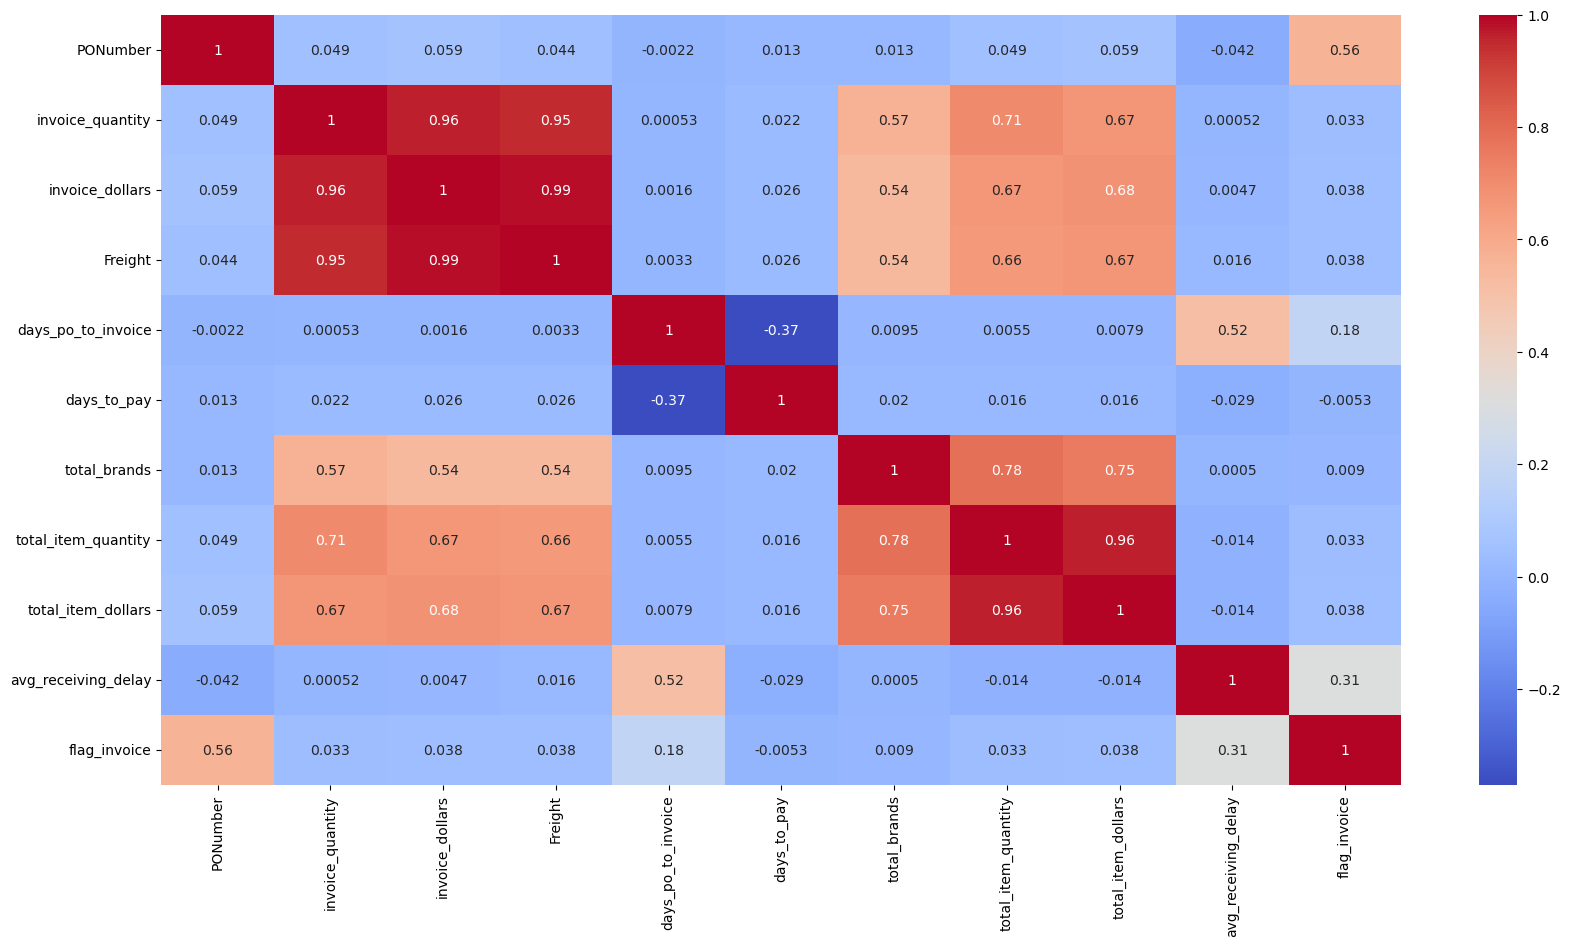

In [16]:
corr=df.corr()
plt.figure(figsize=(20,10))
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.show()

In [17]:
flagged=df[df['flag_invoice']==1]
normal=df[df['flag_invoice']==0]


In [18]:
significant_features=[]
non_significant_features=[]
results =[]

In [22]:
metrics=['invoice_quantity','invoice_dollars','Freight','days_po_to_invoice','days_to_pay','total_brands','total_item_quantity','avg_receiving_delay']


In [23]:
from scipy.stats import ttest_ind
for metric in metrics:
    flagged_mean=flagged[metric].mean()
    normal_mean=flagged[metric].mean()

    t_stat,p_value=ttest_ind(
        flagged[metric].dropna(),
        normal[metric].dropna(),
        equal_var=True
    )
    if p_value<0.05:
        significant_features.append(metric)
        results.append({
        'metric':metric,
        'flagged_mean':flagged_mean.round(2),
        'normal_mean':normal_mean.round(2),
        'p_value':p_value.round(3)
        })
    else:
        non_significant_features.append(metric)
        

In [24]:
significant_features

['invoice_quantity',
 'invoice_dollars',
 'invoice_quantity',
 'invoice_dollars',
 'Freight',
 'days_po_to_invoice',
 'total_item_quantity',
 'avg_receiving_delay']

In [25]:
results

[{'metric': 'invoice_quantity',
  'flagged_mean': np.float64(6728.28),
  'normal_mean': np.float64(6728.28),
  'p_value': np.float64(0.015)},
 {'metric': 'invoice_dollars',
  'flagged_mean': np.float64(65600.61),
  'normal_mean': np.float64(65600.61),
  'p_value': np.float64(0.005)},
 {'metric': 'invoice_quantity',
  'flagged_mean': np.float64(6728.28),
  'normal_mean': np.float64(6728.28),
  'p_value': np.float64(0.015)},
 {'metric': 'invoice_dollars',
  'flagged_mean': np.float64(65600.61),
  'normal_mean': np.float64(65600.61),
  'p_value': np.float64(0.005)},
 {'metric': 'Freight',
  'flagged_mean': np.float64(334.02),
  'normal_mean': np.float64(334.02),
  'p_value': np.float64(0.005)},
 {'metric': 'days_po_to_invoice',
  'flagged_mean': np.float64(17.23),
  'normal_mean': np.float64(17.23),
  'p_value': np.float64(0.0)},
 {'metric': 'total_item_quantity',
  'flagged_mean': np.float64(6728.28),
  'normal_mean': np.float64(6728.28),
  'p_value': np.float64(0.015)},
 {'metric': 'avg

In [27]:
x=df[['invoice_quantity',
 'invoice_dollars',
 'invoice_quantity',
 'invoice_dollars',
 'Freight',
 'days_po_to_invoice',
 'total_item_quantity',
 'avg_receiving_delay']]
y=df['flag_invoice']

In [28]:
x

,invoice_quantity,invoice_dollars,invoice_quantity,invoice_dollars,Freight,days_po_to_invoice,total_item_quantity,avg_receiving_delay
0,6,214.26,6,214.26,3.47,14.0,6,12.000000
1,15,140.55,15,140.55,8.57,16.0,15,10.333333
2,5,106.60,5,106.60,4.61,16.0,5,9.000000
3,10100,137483.78,10100,137483.78,2935.20,23.0,10100,12.614130
4,1935,15527.25,1935,15527.25,429.20,14.0,1935,8.752809
...,...,...,...,...,...,...,...,...
5538,90,1563.00,90,1563.00,8.60,16.0,223,5.871795
5539,4617,37300.48,4617,37300.48,186.50,18.0,24747,5.050500
5540,9848,202815.78,9848,202815.78,932.95,11.0,180,5.000000
5541,24747,149007.56,24747,149007.56,819.54,14.0,43240,8.045541


In [29]:
x.describe()


,invoice_quantity,invoice_dollars,invoice_quantity,invoice_dollars,Freight,days_po_to_invoice,total_item_quantity,avg_receiving_delay
count,5543.000000,5.543000e+03,5543.000000,5.543000e+03,5543.000000,5543.000000,5543.000000,5543.000000
mean,6058.880931,5.807338e+04,6058.880931,5.807338e+04,295.954301,16.424499,6058.880931,7.671541
std,14453.338164,1.402340e+05,14453.338164,1.402340e+05,713.585093,3.127282,14453.338164,1.824496
min,1.000000,4.140000e+00,1.000000,4.140000e+00,0.020000,9.000000,1.000000,3.000000
25%,83.000000,9.678100e+02,83.000000,9.678100e+02,5.020000,14.000000,83.000000,6.129178
50%,423.000000,4.765450e+03,423.000000,4.765450e+03,24.730000,16.000000,423.000000,7.744898
75%,5100.500000,4.458718e+04,5100.500000,4.458718e+04,229.660000,19.000000,5100.500000,9.083804
max,141660.000000,1.660436e+06,141660.000000,1.660436e+06,8468.220000,23.000000,141660.000000,13.000000


In [71]:
x=df[['invoice_quantity',
 'total_brands',
 'invoice_dollars',
 'Freight',
 'days_po_to_invoice',
 'total_item_quantity',
 'total_item_dollars']]
y=df['flag_invoice']

In [72]:
from sklearn.preprocessing import StandardScaler , MinMaxScaler
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.25,random_state=42)
scale=StandardScaler()
x_train_scaled=scale.fit_transform(x_train)
x_test_scaled=scale.transform(x_test)

In [73]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [74]:
model1=LogisticRegression(random_state=42)
model1.fit(x_train_scaled,y_train)

model2=DecisionTreeClassifier(random_state=42)
model2.fit(x_train_scaled,y_train)

model3=RandomForestClassifier(random_state=42)
model3.fit(x_train_scaled,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [75]:
from sklearn.metrics import accuracy_score,classification_report
def evaluate_model(model,x_test,y_test,model_name):
    pred=model.predict(x_test)
    
    cr=classification_report(y_test,pred)
    acc_score=accuracy_score(y_test,pred)

    print(f"\n {model_name} Performance:")
    print(f"acc_score : {acc_score:.2f}")
    print(f"classification report :{cr}")


In [76]:
evaluate_model(model1,x_test_scaled,y_test,'Logistic Regression')
evaluate_model(model2,x_test_scaled,y_test,'Decision Tree Classifier')
evaluate_model(model3,x_test_scaled,y_test,'Random Forest')


 Logistic Regression Performance:
acc_score : 0.66
classification report :              precision    recall  f1-score   support

           0       0.66      0.98      0.79       907
           1       0.56      0.05      0.09       479

    accuracy                           0.66      1386
   macro avg       0.61      0.51      0.44      1386
weighted avg       0.63      0.66      0.55      1386


 Decision Tree Classifier Performance:
acc_score : 0.81
classification report :              precision    recall  f1-score   support

           0       0.83      0.89      0.86       907
           1       0.76      0.66      0.71       479

    accuracy                           0.81      1386
   macro avg       0.79      0.77      0.78      1386
weighted avg       0.81      0.81      0.81      1386


 Random Forest Performance:
acc_score : 0.87
classification report :              precision    recall  f1-score   support

           0       0.84      0.98      0.91       907
           1 

In [77]:
imp=model3.feature_importances_

In [78]:
feature_importances=pd.DataFrame({
    'feature_name':x_train.columns,
    'importance':imp})
feature_importances

,feature_name,importance
0,invoice_quantity,0.154488
1,total_brands,0.082353
2,invoice_dollars,0.149391
3,Freight,0.157755
4,days_po_to_invoice,0.077072
5,total_item_quantity,0.169671
6,total_item_dollars,0.209270


In [83]:
#selecting new features after feature_impoartances
x=df[['total_item_dollars','total_item_quantity','invoice_dollars','Freight','invoice_quantity']]
y=df['flag_invoice']

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.25,random_state=42)
scaler=StandardScaler()
x_train_scale=scaler.fit_transform(x_train)
x_test_scale=scaler.transform(x_test)

model=RandomForestClassifier(random_state=42,n_jobs=-1)
model.fit(x_train_scale,y_train)
evaluate_model(model,x_test_scale,y_test,'Random Forest')


 Random Forest Performance:
acc_score : 0.88
classification report :              precision    recall  f1-score   support

           0       0.86      0.98      0.91       907
           1       0.94      0.69      0.80       479

    accuracy                           0.88      1386
   macro avg       0.90      0.84      0.86      1386
weighted avg       0.89      0.88      0.87      1386



In [95]:
param_grid={
    'n_estimators':[51,101,151],
    'max_depth':[3,4,5,6],
    'min_samples_split':[2,3,4,5],
    'criterion':['gini','entropy']
}

In [98]:
from sklearn.model_selection import GridSearchCV

grid_model=GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=3,
    n_jobs=-1,
)
grid_model.fit(x_train_scale,y_train)
grid_model.best_params_


{'criterion': 'gini',
 'max_depth': 6,
 'min_samples_split': 2,
 'n_estimators': 151}

In [99]:
evaluate_model(grid_model,x_test_scale,y_test,'Grid ')


 Grid  Performance:
acc_score : 0.79
classification report :              precision    recall  f1-score   support

           0       0.76      1.00      0.86       907
           1       0.99      0.40      0.57       479

    accuracy                           0.79      1386
   macro avg       0.88      0.70      0.72      1386
weighted avg       0.84      0.79      0.76      1386



In [102]:
model=RandomForestClassifier(
    n_estimators=151, 
    max_depth=None, # just tried to add none 
    min_samples_split=2,
    random_state=42,
    n_jobs=-1)
model.fit(x_train_scale,y_train)
evaluate_model(model,x_test_scale,y_test,'Random Forest')


 Random Forest Performance:
acc_score : 0.88
classification report :              precision    recall  f1-score   support

           0       0.86      0.98      0.91       907
           1       0.94      0.69      0.80       479

    accuracy                           0.88      1386
   macro avg       0.90      0.83      0.85      1386
weighted avg       0.89      0.88      0.87      1386

